#  Прогнозирование заказов такси

Компания «Чётенькое такси» собрала исторические данные о заказах такси в аэропортах. Чтобы привлекать больше водителей в период пиковой нагрузки, нужно спрогнозировать количество заказов такси на следующий час. Постройте модель для такого предсказания.

Значение метрики *RMSE* на тестовой выборке должно быть не больше 48.

Вам нужно:

1. Загрузить данные и выполнить их ресемплирование по одному часу.
2. Проанализировать данные.
3. Обучить разные модели с различными гиперпараметрами. Сделать тестовую выборку размером 10% от исходных данных.
4. Проверить данные на тестовой выборке и сделать выводы.


Данные лежат в файле `taxi.csv`. Количество заказов находится в столбце `num_orders` (от англ. *number of orders*, «число заказов»).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

RANDOM_STATE = 12345

## Подготовка

In [2]:
data = pd.read_csv('https://code.s3.yandex.net/datasets/taxi.csv', index_col=[0], parse_dates=[0])
data.sort_index(inplace=True)

print('Индекс монотонный:', data.index.is_monotonic)
data.info()
display(data.head())

Индекс монотонный: True
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB


,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


In [3]:
print('Пропусков в num_orders:', data['num_orders'].isna().sum())
print('Дубликатов меток времени:', data.index.duplicated().sum())
print('Отрицательных значений:', (data['num_orders'] < 0).sum())

full_range = pd.date_range(data.index.min(), data.index.max(), freq='10T')
print('Ожидаемое число 10-минутных интервалов:', len(full_range))
print('Фактическое число записей:', len(data))
print('Пропущенных интервалов:', len(full_range.difference(data.index)))

print('\nШаги между соседними записями:')
print(data.index.to_series().diff().value_counts())

Пропусков в num_orders: 0
Дубликатов меток времени: 0
Отрицательных значений: 0
Ожидаемое число 10-минутных интервалов: 26496
Фактическое число записей: 26496
Пропущенных интервалов: 0

Шаги между соседними записями:
0 days 00:10:00    26495
Name: datetime, dtype: int64


In [4]:
data = data.resample('1h').sum()

print('Период:', data.index.min(), '—', data.index.max())
print('Размер после ресемплирования:', data.shape)
print('Пропусков:', data.isna().sum().sum())
display(data.describe())

Период: 2018-03-01 00:00:00 — 2018-08-31 23:00:00
Размер после ресемплирования: (4416, 1)
Пропусков: 0


,num_orders
count,4416.000000
mean,84.422781
std,45.023853
min,0.000000
25%,54.000000
50%,78.000000
75%,107.000000
max,462.000000


**Вывод по подготовке**

- Данные загружены, столбец `datetime` распознан как дата и сделан индексом. Индекс монотонный, даты идут в хронологическом порядке.
- Дубликатов меток времени, пропусков и отрицательных значений нет. Интервал между записями везде ровно 10 минут, пропущенных интервалов нет.
- Исходный интервал — 10 минут, 26 496 записей. После ресемплирования по одному часу с суммированием заказов осталось 4 416 строк.
- Период: с 1 марта по 31 августа 2018 года. Пропусков нет.
- В среднем 84 заказа в час, медиана 78. Максимум — 462 заказа в час, это редкие выбросы. Минимум 0.

## Анализ

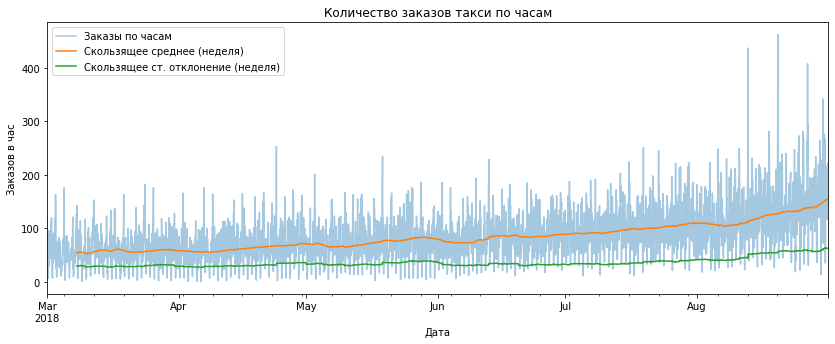

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
data['num_orders'].plot(ax=ax, alpha=0.4, label='Заказы по часам')
data['num_orders'].rolling(24 * 7).mean().plot(ax=ax, label='Скользящее среднее (неделя)')
data['num_orders'].rolling(24 * 7).std().plot(ax=ax, label='Скользящее ст. отклонение (неделя)')
ax.set_title('Количество заказов такси по часам')
ax.set_xlabel('Дата')
ax.set_ylabel('Заказов в час')
ax.legend()
plt.show()

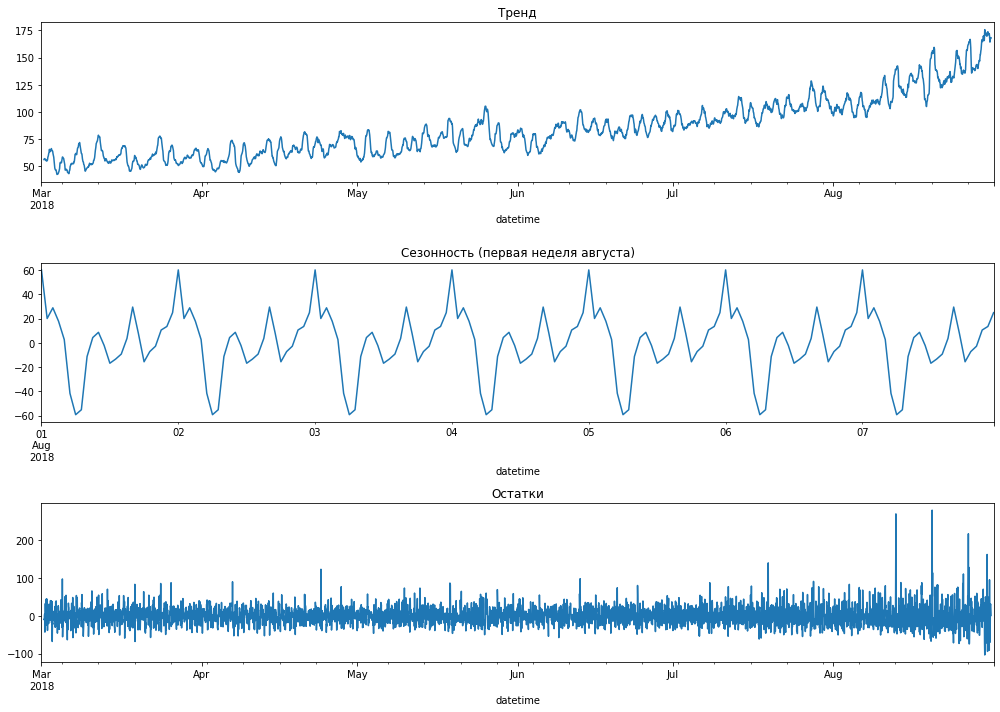

In [6]:
decomposed = seasonal_decompose(data['num_orders'])

fig, axes = plt.subplots(3, 1, figsize=(14, 10))
decomposed.trend.plot(ax=axes[0], title='Тренд')
decomposed.seasonal['2018-08-01':'2018-08-07'].plot(ax=axes[1], title='Сезонность (первая неделя августа)')
decomposed.resid.plot(ax=axes[2], title='Остатки')
plt.tight_layout()
plt.show()

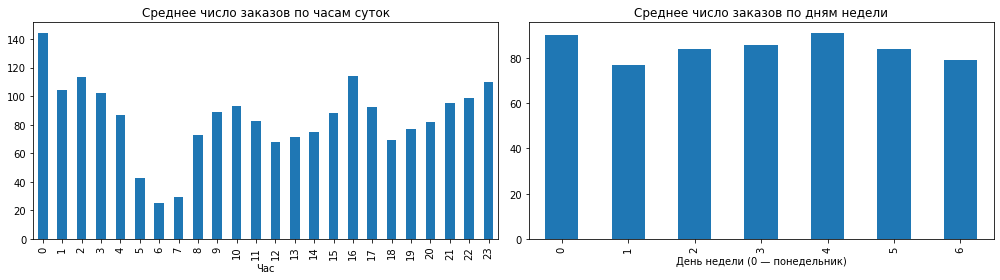

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

data.groupby(data.index.hour)['num_orders'].mean().plot(kind='bar', ax=axes[0])
axes[0].set_title('Среднее число заказов по часам суток')
axes[0].set_xlabel('Час')

data.groupby(data.index.dayofweek)['num_orders'].mean().plot(kind='bar', ax=axes[1])
axes[1].set_title('Среднее число заказов по дням недели')
axes[1].set_xlabel('День недели (0 — понедельник)')

plt.tight_layout()
plt.show()

**Вывод по анализу**

- **Тренд.** Число заказов растёт на всём периоде: недельное скользящее среднее увеличилось примерно с 55 заказов в час в марте до 150 в конце августа. Особенно быстро рост идёт во второй половине августа.
- **Разброс.** Вместе со средним растёт и скользящее стандартное отклонение, примерно с 30 до 60. В августе появляются резкие пики до 400–460 заказов в час. Ряд нестационарный.
- **Суточная сезонность.** Это самая сильная закономерность ряда, период 24 часа. Пик заказов приходится на полночь (около 145 в час), минимум — на 6–7 утра (около 25–30). Есть локальные пики около 10 и 16 часов. Скорее всего, они связаны с расписанием прилётов.
- **Недельная сезонность.** На графике тренда видны регулярные колебания с периодом около недели. Различия по дням недели слабее суточных: больше всего заказов в понедельник и пятницу (около 90 в час), меньше всего во вторник и воскресенье (77–79).
- **Остатки** в основном колеблются около нуля, но в августе есть крупные выбросы до 200–280. Модели их не предсказать, поэтому ошибка на тесте будет выше, чем на кросс-валидации.

**Признаки для обучения:** час и день недели (суточная и недельная сезонность), отстающие значения, включая лаг 168 (тот же час неделю назад), и скользящее среднее за 24 часа без текущего значения (тренд).

## Обучение

In [8]:
def make_features(df, max_lag, rolling_mean_size):
    df = df.copy()
    df['dayofweek'] = df.index.dayofweek
    df['hour'] = df.index.hour

    for lag in range(1, max_lag + 1):
        df['lag_{}'.format(lag)] = df['num_orders'].shift(lag)

    df['rolling_mean'] = df['num_orders'].shift().rolling(rolling_mean_size).mean()
    return df


def split_data(df):
    train, test = train_test_split(df, shuffle=False, test_size=0.1)
    train = train.dropna()
    return (train.drop('num_orders', axis=1), train['num_orders'],
            test.drop('num_orders', axis=1), test['num_orders'])


tscv = TimeSeriesSplit(n_splits=5)

In [9]:
for max_lag in [24, 48, 168]:
    features_train, target_train, _, _ = split_data(make_features(data, max_lag, 24))
    scores = cross_val_score(LinearRegression(), features_train, target_train,
                             cv=tscv, scoring='neg_root_mean_squared_error')
    print(f'max_lag={max_lag}: RMSE на кросс-валидации = {-scores.mean():.2f}')

max_lag=24: RMSE на кросс-валидации = 27.13
max_lag=48: RMSE на кросс-валидации = 24.73
max_lag=168: RMSE на кросс-валидации = 22.55


In [10]:
MAX_LAG = 168          # лучшее число лагов по результатам кросс-валидации выше
ROLLING_MEAN_SIZE = 24

data_features = make_features(data, MAX_LAG, ROLLING_MEAN_SIZE)
features_train, target_train, features_test, target_test = split_data(data_features)

print('Обучающая:', features_train.shape, features_train.index.min(), '—', features_train.index.max())
print('Тестовая:', features_test.shape, features_test.index.min(), '—', features_test.index.max())

Обучающая: (3806, 171) 2018-03-08 00:00:00 — 2018-08-13 13:00:00
Тестовая: (442, 171) 2018-08-13 14:00:00 — 2018-08-31 23:00:00


In [11]:
models = {
    'LinearRegression': (LinearRegression(), {}),
    'RandomForest': (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                     {'n_estimators': [100], 'max_depth': [10, 20]}),
    'LightGBM': (LGBMRegressor(random_state=RANDOM_STATE),
                 {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1], 'num_leaves': [31, 63]}),
    'CatBoost': (CatBoostRegressor(random_state=RANDOM_STATE, verbose=0),
                 {'iterations': [300], 'depth': [4, 6], 'learning_rate': [0.05, 0.1]}),
}

results = []
best_models = {}

for name, (model, params) in models.items():
    grid = GridSearchCV(model, params, cv=tscv, scoring='neg_root_mean_squared_error')
    grid.fit(features_train, target_train)
    best_models[name] = grid.best_estimator_
    results.append({'model': name,
                    'RMSE_CV': -grid.best_score_,
                    'best_params': grid.best_params_})
    print(f'{name}: RMSE = {-grid.best_score_:.2f}, {grid.best_params_}')

results = pd.DataFrame(results).sort_values('RMSE_CV').reset_index(drop=True)
display(results)

LinearRegression: RMSE = 22.55, {}
RandomForest: RMSE = 22.95, {'max_depth': 20, 'n_estimators': 100}
LightGBM: RMSE = 22.87, {'learning_rate': 0.05, 'n_estimators': 100, 'num_leaves': 31}
CatBoost: RMSE = 22.40, {'depth': 4, 'iterations': 300, 'learning_rate': 0.05}


,model,RMSE_CV,best_params
0,CatBoost,22.401676,"{'depth': 4, 'iterations': 300, 'learning_rate..."
1,LinearRegression,22.549463,{}
2,LightGBM,22.869289,"{'learning_rate': 0.05, 'n_estimators': 100, '..."
3,RandomForest,22.949282,"{'max_depth': 20, 'n_estimators': 100}"


**Вывод по обучению**

- Признаки: час, день недели, 168 отстающих значений и скользящее среднее за 24 часа. Число лагов подбирали на линейной регрессии: при 24 лагах RMSE на кросс-валидации 27,13, при 48 — 24,73, при 168 — 22,55. Значение неделю назад заметно улучшает прогноз.
- Тестовая выборка — последние 10% данных, 442 часа (с 13 по 31 августа). Обучающая — 3 806 часов. Первые 168 часов удалены, потому что для них нет всех лагов.
- Модели оценивали на кросс-валидации `TimeSeriesSplit` с 5 фолдами. Данные в ней не перемешиваются, валидация всегда идёт после обучения, поэтому утечки из будущего нет.

| Модель | Лучшие гиперпараметры | RMSE на CV |
|---|---|---|
| CatBoost | depth=4, iterations=300, learning_rate=0.05 | 22,40 |
| LinearRegression | — | 22,55 |
| LightGBM | learning_rate=0.05, n_estimators=100, num_leaves=31 | 22,87 |
| RandomForest | max_depth=20, n_estimators=100 | 22,95 |

- Лучший результат у CatBoost, но все четыре модели близки: разница меньше 0,6. Основную информацию дают лаги, поэтому даже линейная регрессия почти не уступает бустингу.
- На тесте проверяем CatBoost.

## Тестирование

In [12]:
best_name = results.loc[0, 'model']
best_model = best_models[best_name]

pred_test = best_model.predict(features_test)
rmse_test = np.sqrt(mean_squared_error(target_test, pred_test))

pred_previous = target_test.shift()
pred_previous.iloc[0] = target_train.iloc[-1]
rmse_baseline = np.sqrt(mean_squared_error(target_test, pred_previous))

print(f'Лучшая модель: {best_name}')
print(f'RMSE на тестовой выборке: {rmse_test:.2f}')
print(f'RMSE прогноза предыдущим значением: {rmse_baseline:.2f}')

Лучшая модель: CatBoost
RMSE на тестовой выборке: 36.95
RMSE прогноза предыдущим значением: 58.86


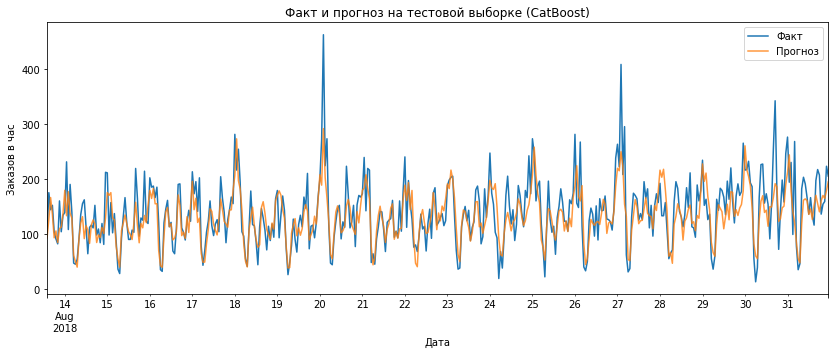

In [13]:
fig, ax = plt.subplots(figsize=(14, 5))
target_test.plot(ax=ax, label='Факт')
pd.Series(pred_test, index=target_test.index).plot(ax=ax, label='Прогноз', alpha=0.8)
ax.set_title(f'Факт и прогноз на тестовой выборке ({best_name})')
ax.set_xlabel('Дата')
ax.set_ylabel('Заказов в час')
ax.legend()
plt.show()

**Общий вывод**

- Данные о заказах такси за март–август 2018 года ресемплированы по часу. В ряду есть восходящий тренд, сильная суточная сезонность (пик в полночь, минимум в 6 утра) и более слабая недельная.
- Для прогноза на следующий час созданы признаки: час, день недели, 168 отстающих значений и скользящее среднее за 24 часа.
- Обучены четыре модели с подбором гиперпараметров на `TimeSeriesSplit`. Лучшая — **CatBoost** (depth=4, iterations=300, learning_rate=0.05).
- **RMSE на тестовой выборке — 36,95**, что укладывается в требование не больше 48.
- Модель адекватна: наивный прогноз предыдущим значением даёт RMSE 58,86, то есть CatBoost ошибается примерно на 37% меньше.
- На тесте ошибка выше, чем на кросс-валидации (36,95 против 22,40). Тест приходится на вторую половину августа, где заказов больше всего, а разброс и выбросы максимальны.
- По графику модель хорошо повторяет суточный цикл и общий уровень, но недооценивает резкие пики (например, 20 и 27 августа, больше 400 заказов). Для бизнеса это значит, что в обычные часы на прогноз можно опираться, а в аномальные пики водителей всё равно может не хватать.